# 7-3 RFM 用户分层

请选择 `Python (da-course)` 内核，从 `notebooks/` 打开。本课基于 2025 年已完成订单（`orders.csv`），以 `2026-01-01` 为观察基准日，对 2427 位购买客户做 RFM 八类分层。

> **这是参考答案版**，保留完整示例与解法。代码格下方的输出会在运行后出现。
> 建议先在 `notebooks/` 文件夹里的学生版自己做一遍，卡住了再来这里对照。

In [1]:
import sys
sys.path.insert(0, "..")
from dacheck import check, hint, setup_chinese_font
import pandas as pd
import matplotlib.pyplot as plt

读取订单表，筛出已完成订单。

In [2]:
orders = pd.read_csv("../data/shop/orders.csv", parse_dates=["order_time"], encoding="utf-8-sig")
completed = orders.loc[orders["status"].eq("已完成")].copy()
REF_DATE = pd.Timestamp("2026-01-01")
print("已完成订单数：", len(completed), "购买客户数：", completed["customer_id"].nunique())

已完成订单数： 13996 购买客户数： 2427


## 1. 计算 R、F、M 原始值与中位数阈值

- `R`（Recency）：最近一次消费距基准日的天数，**越小代表越活跃**。
- `F`（Frequency）：窗口内唯一已完成订单数，越大越好。
- `M`（Monetary）：窗口内已完成实付金额总和，越大越好。

In [3]:
rfm = completed.groupby("customer_id", as_index=False).agg(
    last_time=("order_time", "max"),
    F=("order_id", "nunique"),
    M=("pay_amount", "sum"),
)
rfm["R"] = (REF_DATE - rfm["last_time"]).dt.days
print("中位数阈值：", rfm[["R", "F", "M"]].median().to_dict())
rfm[["customer_id", "R", "F", "M"]].head()

中位数阈值： {'R': 50.0, 'F': 3.0, 'M': 376.2}


,customer_id,R,F,M
0,C00001,84,6,416.1
1,C00003,156,2,51.0
2,C00004,223,1,22.0
3,C00005,243,2,702.0
4,C00006,12,5,859.0


## 2. 按中位数划分八类客户并可视化

In [4]:
SEG_MAP = {
    (True, True, True): "重要价值客户",
    (False, True, True): "重要保持客户",
    (True, False, True): "重要发展客户",
    (False, False, True): "重要挽留客户",
    (True, True, False): "一般价值客户",
    (False, True, False): "一般保持客户",
    (True, False, False): "一般发展客户",
    (False, False, False): "一般挽留客户",
}
r_med, f_med, m_med = rfm["R"].median(), rfm["F"].median(), rfm["M"].median()
rfm["segment"] = [
    SEG_MAP[(r <= r_med, f >= f_med, m >= m_med)]
    for r, f, m in zip(rfm["R"], rfm["F"], rfm["M"])
]
seg_summary = rfm.groupby("segment", as_index=False).agg(
    customers=("customer_id", "nunique"),
    total_m=("M", "sum"),
).sort_values("total_m", ascending=False)
seg_summary["rev_share"] = seg_summary["total_m"] / seg_summary["total_m"].sum()
seg_summary

,segment,customers,total_m,rev_share
4,重要价值客户,756,1247488.8,0.699120
5,重要保持客户,326,257596.0,0.144362
3,一般挽留客户,594,80167.9,0.044928
1,一般保持客户,195,48269.1,0.027051
7,重要挽留客户,87,48014.7,0.026908
2,一般发展客户,291,43357.2,0.024298
0,一般价值客户,133,35825.7,0.020077
6,重要发展客户,45,23651.7,0.013255


画横向条形图观察各分层销售额贡献。

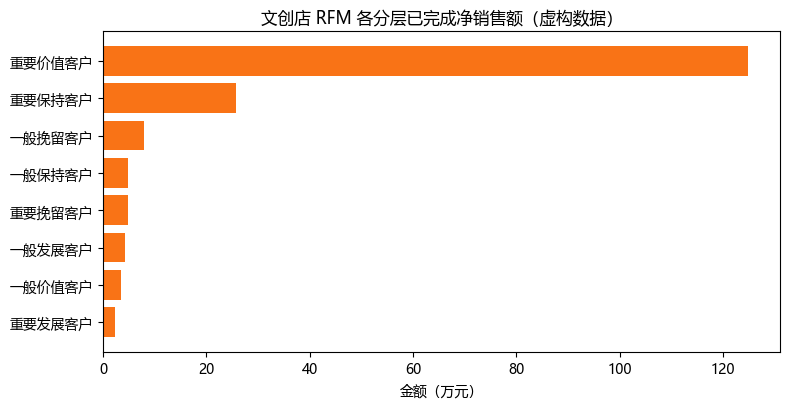

In [5]:
setup_chinese_font()
plot_df = seg_summary.sort_values("total_m", ascending=True)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(plot_df["segment"], plot_df["total_m"] / 10000, color="#f97316")
ax.set(title="文创店 RFM 各分层已完成净销售额（虚构数据）", xlabel="金额（万元）", ylabel="")
fig.tight_layout()
plt.show()

## 练习 7-3.1 计算每位购买客户的 R、F、M 原始值

以 `REF_DATE = pd.Timestamp("2026-01-01")` 为基准日，对已完成订单按 `customer_id` 计算 `R, F, M`，输出 `customer_id, R, F, M` 四列并按 `customer_id` 升序排列。

In [6]:
done_ex = orders.loc[orders["status"].eq("已完成")]
rfm_ex = done_ex.groupby("customer_id", as_index=False).agg(
    last_time=("order_time", "max"),
    F=("order_id", "nunique"),
    M=("pay_amount", "sum"),
)
rfm_ex["R"] = (pd.Timestamp("2026-01-01") - rfm_ex["last_time"]).dt.days
ans_7_3_1 = rfm_ex[["customer_id", "R", "F", "M"]].sort_values("customer_id").reset_index(drop=True)
check("7-3.1", ans_7_3_1)

True

## 练习 7-3.2 计算 R、F、M 的中位数阈值

计算 2427 位购买客户 `R, F, M` 的中位数，存入字典 `ans_7_3_2`（键：`R_med, F_med, M_med`）。

In [7]:
ans_7_3_2 = {
    "R_med": float(rfm["R"].median()),
    "F_med": float(rfm["F"].median()),
    "M_med": float(rfm["M"].median()),
}
check("7-3.2", ans_7_3_2)

True

## 练习 7-3.3 RFM 八类客户分层汇总

按 `R <= R_med`、`F >= F_med`、`M >= M_med` 映射到八类客户名称，统计各分层的 `customers` 与 `total_m`，按 `total_m` 降序排列。

In [8]:
ans_7_3_3 = (
    rfm.groupby("segment", as_index=False)
    .agg(customers=("customer_id", "nunique"), total_m=("M", "sum"))
    .sort_values("total_m", ascending=False)
    .reset_index(drop=True)
)
check("7-3.3", ans_7_3_3)

True

## 练习 7-3.4 重要价值客户的人数占比与金额贡献占比

计算“重要价值客户”的人数占比 `customer_share` 与金额占比 `revenue_share`（0~1 小数）。

In [9]:
vip = rfm.loc[rfm["segment"].eq("重要价值客户")]
ans_7_3_4 = {
    "customer_share": len(vip) / len(rfm),
    "revenue_share": vip["M"].sum() / rfm["M"].sum(),
}
check("7-3.4", ans_7_3_4)

True